## Part 1: Data Loading & Initial Inspection


# 1.Import important libraries (pandas, numpy, matplotlib, seaborn, sklearn).


In [ ]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 

# 2.Load healthcare-dataset-stroke-data.csv into DataFrame df


In [50]:
df = pd.read_csv("C:\\Users\\Infotech\\OneDrive\\Desktop\\Ass 4\\healthcare-dataset-stroke-data.csv")

# 3.Display first 5 rows using df.head()


In [51]:
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


# 4.Use df.info() to check data types, non-null values, memory usage


In [52]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 479.2 KB


# 5.Use df.describe() for statistical summaries

In [53]:
df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


## Part 2: Exploratory Data Analysis & Visualization







# 1.Create countplot for stroke column (class distribution)


Text(0, 0.5, 'Count')

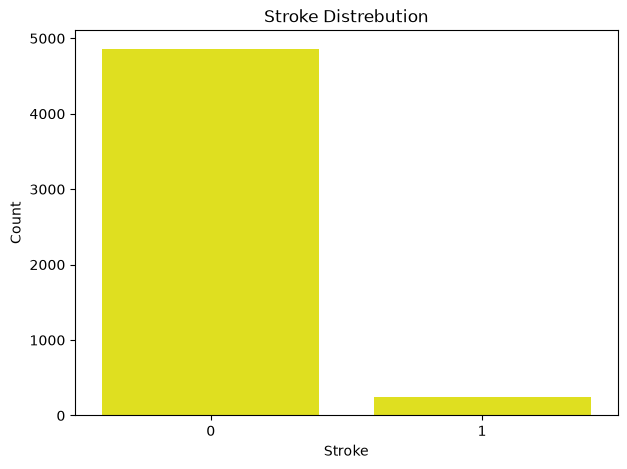

In [54]:
plt.figure(figsize = (7 , 5))
sns.countplot(data = df , x = "stroke"  , color = "Yellow")
plt.title("Stroke Distrebution")
plt.xlabel("Stroke")
plt.ylabel("Count")

# 2.Create countplots with hue='stroke' for gender, work_type, smoking_status using subplots


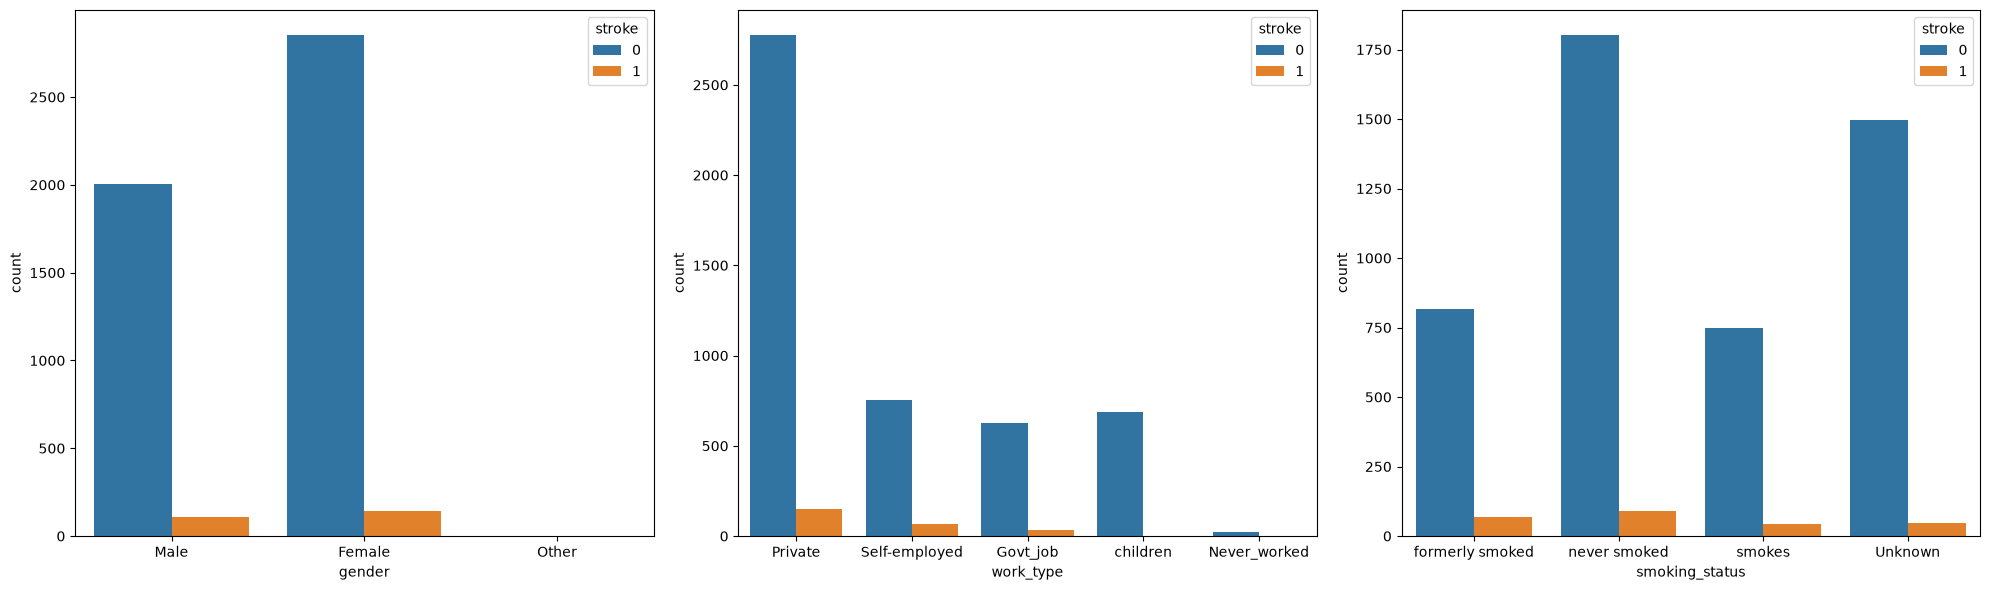

In [55]:
fig , axes = plt.subplots( 1 , 3 , figsize = (20 , 6))
sns.countplot(data = df , x = "gender" , hue = "stroke" , ax = axes[0])
sns.countplot(data = df , x = "work_type" , hue = "stroke" , ax = axes[1])
sns.countplot(data = df , x = "smoking_status" , hue = "stroke"  , ax= axes[2])
plt.tight_layout()
plt.show()

# 3.Drop 'Other' gender record (only 1 exists)


In [56]:
df = df[df["gender"] != "Other"].copy()

In [57]:
df["gender"].value_counts()

gender
Female    2994
Male      2115
Name: count, dtype: int64

# 4.Create histograms/KDE plots for age, avg_glucose_level, bmi using subplots


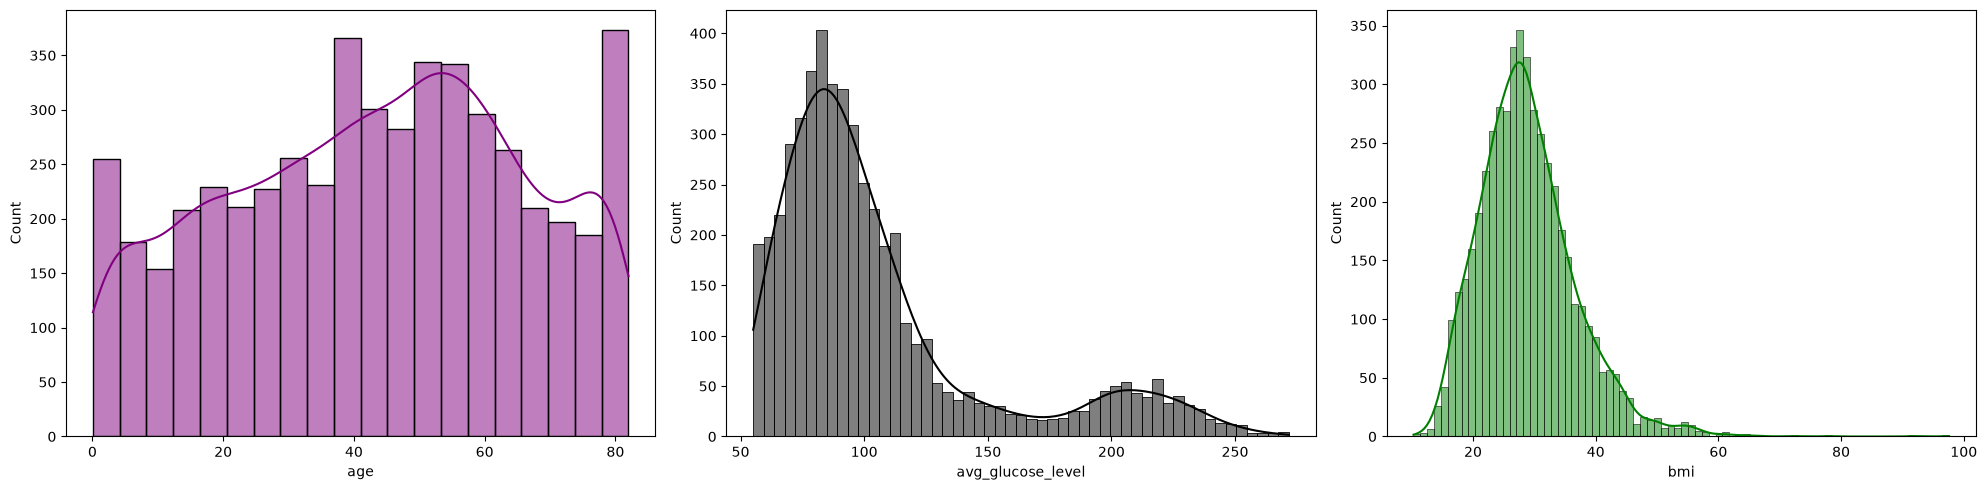

In [58]:
fig , axes = plt.subplots(1 , 3 , figsize = (20 , 5) )
sns.histplot(data = df , x = "age" , kde = True , ax =axes[0] , color = "purple") 
sns.histplot(data = df , x = "avg_glucose_level" , kde = True , ax = axes[1] , color = "black")
sns.histplot(data = df , x = "bmi" , kde = True , ax = axes[2] , color = "green")
plt.tight_layout()
plt.show()

# 5.Create correlation heatmap using selected numerical features and stroke

In [59]:
numerical_features = [
    "age",
    "avg_glucose_level",
    "bmi",
    "stroke"
]

In [60]:
correlation = df[numerical_features].corr()

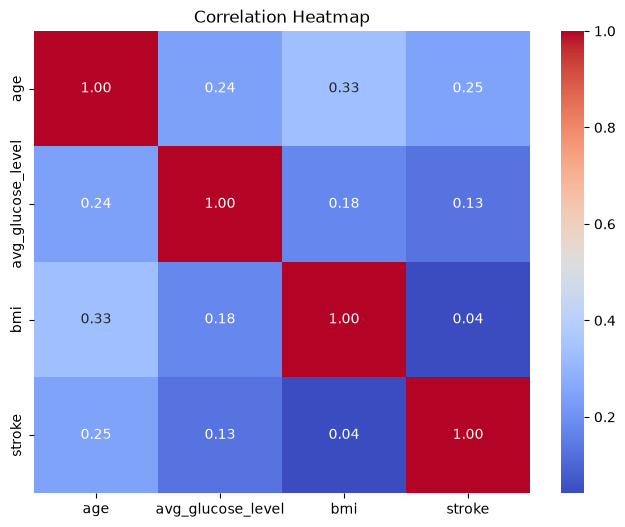

In [61]:
plt.figure(figsize = (8 , 6))
sns.heatmap(correlation , annot = True , cmap = "coolwarm" , fmt = ".2f")
plt.title("Correlation Heatmap") 
plt.show()

# Part 3: Data Preprocessing (Cleaning)


# 1.Check for missing values using df.isnull().sum()


In [62]:
df.isnull().sum()

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

# 2.Fill bmi missing values using mean or median


In [63]:
df["bmi"] = df["bmi"].fillna(df["bmi"].median())

# 3.Verify no missing values remain


In [64]:
df.isnull().sum()

id                   0
gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64

# 4.Check for duplicates and remove them if any exist


In [65]:
df.duplicated().sum()

np.int64(0)

# 5.Drop id column (no predictive power)


In [66]:
df = df.drop(columns = ["id"])

In [ ]:
 df.columns

Index(['gender', 'age', 'hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type', 'avg_glucose_level', 'bmi',
       'smoking_status', 'stroke'],
      dtype='str')

# 6.Create boxplot for avg_glucose_level to detect outliers and remove if needed

In [70]:
Q1 = df["avg_glucose_level"].quantile(0.25)
Q3 = df["avg_glucose_level"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
outliers = df[(df["avg_glucose_level"] < lower_bound) | (df["avg_glucose_level"] > upper_bound)]
outliers.shape

(627, 11)

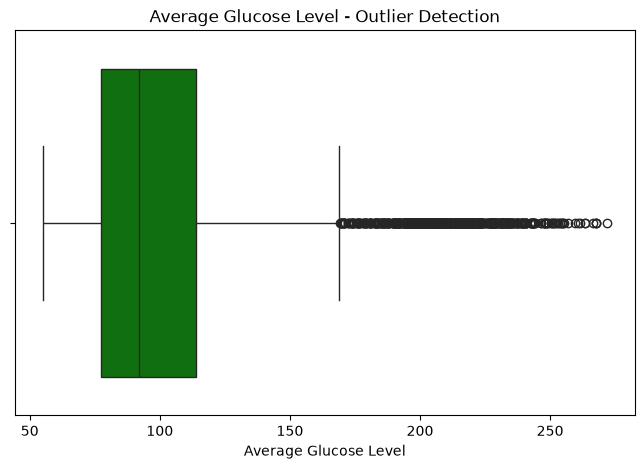

In [69]:
plt.figure(figsize = ( 8 , 5 ))
sns.boxplot(data = df , x = "avg_glucose_level" , color = "Green")
plt.title("Average Glucose Level - Outlier Detection")
plt.xlabel("Average Glucose Level")
plt.show()

# Part 4: Feature Transformation


# 1.Encode categorical variables: gender, work_type, smoking_status, ever_married, Residence_type


In [75]:
categorical_columns = [
    "gender",
    "work_type",
    "smoking_status",
    "ever_married",
    "Residence_type"
]

# 2.Reset DataFrame index


In [76]:
df = df.reset_index(drop = True)

# 3.Apply one-hot encoding using pd.get_dummies() or OneHotEncoder

In [77]:
df = pd.get_dummies(df , columns = categorical_columns , dtype = int)

In [78]:
df.head()

,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke,gender_Female,gender_Male,work_type_Govt_job,work_type_Never_worked,...,work_type_Self-employed,work_type_children,smoking_status_Unknown,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,ever_married_No,ever_married_Yes,Residence_type_Rural,Residence_type_Urban
0,67.0,0,1,228.69,36.6,1,0,1,0,0,...,0,0,0,1,0,0,0,1,0,1
1,61.0,0,0,202.21,28.1,1,1,0,0,0,...,1,0,0,0,1,0,0,1,1,0
2,80.0,0,1,105.92,32.5,1,0,1,0,0,...,0,0,0,0,1,0,0,1,1,0
3,49.0,0,0,171.23,34.4,1,1,0,0,0,...,0,0,0,0,0,1,0,1,0,1
4,79.0,1,0,174.12,24.0,1,1,0,0,0,...,1,0,0,0,1,0,0,1,1,0


In [79]:
df.dtypes

age                               float64
hypertension                        int64
heart_disease                       int64
avg_glucose_level                 float64
bmi                               float64
stroke                              int64
gender_Female                       int64
gender_Male                         int64
work_type_Govt_job                  int64
work_type_Never_worked              int64
work_type_Private                   int64
work_type_Self-employed             int64
work_type_children                  int64
smoking_status_Unknown              int64
smoking_status_formerly smoked      int64
smoking_status_never smoked         int64
smoking_status_smokes               int64
ever_married_No                     int64
ever_married_Yes                    int64
Residence_type_Rural                int64
Residence_type_Urban                int64
dtype: object

In [80]:
df.select_dtypes(include = "object").columns

Index([], dtype='str')

# Part 5: Data Splitting


In [86]:
from sklearn.model_selection import train_test_split


# 1.Separate features X and target y


In [82]:
x = df.drop(columns = ["stroke"])
y = df["stroke"]

# 2.Use train_test_split() with 80/20 ratio and random_state=42


In [83]:
x_train , x_test , y_train , y_test = train_test_split(x , y , test_size = 0.2 , random_state = 42)

# 3.Verify shapes of X_train, X_test, y_train, y_test

In [85]:
print("X_Train:" , x_train.shape)
print("X_Test:" , x_test.shape)
print("Y_train:" , y_train.shape)
print("Y_test:" , y_test.shape)

X_Train: (4087, 20)
X_Test: (1022, 20)
Y_train: (4087,)
Y_test: (1022,)


# Part 6: Feature Scaling

# 1.Import StandardScaler or MinMaxScaler


In [94]:
from sklearn.preprocessing import StandardScaler

# 2.Scale numerical features: age, avg_glucose_level, bmi


In [89]:
numerical_features = ["age","avg_glucose_level" , "bmi"]

In [90]:
scaler = StandardScaler()

# 3.Fit scaler on training data only, then transform both train and test sets

In [91]:
x_train[numerical_features] = scaler.fit_transform(x_train[numerical_features])

In [92]:
x_test[numerical_features] = scaler.transform(x_test[numerical_features])

In [93]:
x_train[numerical_features].head()

,age,avg_glucose_level,bmi
802,1.588594,0.142703,-0.048907
3926,0.836881,-0.392719,0.957224
2337,-0.976075,-1.026771,0.621847
3909,-0.533891,-0.890714,0.196176
1886,-0.533891,-1.024350,-1.158232


In [96]:
x_train[numerical_features].agg(["mean" , "std"])

,age,avg_glucose_level,bmi
mean,2.781670e-17,1.747236e-16,-1.636404e-16
std,1.000122e+00,1.000122e+00,1.000122e+00


# Part 7: Handling Class Imbalance
# 1.Check distribution of stroke
# 2.Apply oversampling/undersampling or SMOTE
# 3.Verify balanced distribution

# 1.Check distribution of stroke


In [97]:
y_train.value_counts()

stroke
0    3900
1     187
Name: count, dtype: int64

In [98]:
y_train.value_counts(normalize = True) * 100

stroke
0    95.424517
1     4.575483
Name: proportion, dtype: float64

# 2.Apply oversampling/undersampling or SMOTE


In [99]:
from imblearn.over_sampling import SMOTE

In [100]:
smote = SMOTE(random_state = 42)
x_train_balanced , y_train_balanced = smote.fit_resample(x_train , y_train)

# 3.Verify balanced distribution

In [101]:
y_train_balanced .value_counts()

stroke
0    3900
1    3900
Name: count, dtype: int64

In [102]:
y_train_balanced .value_counts(normalize = True) * 100

stroke
0    50.0
1    50.0
Name: proportion, dtype: float64

In [104]:
print("Original training shape:" , x_train.shape)
print("Balanced training shape:" , x_train_balanced)
print("Original target shape :" , y_train.shape)
print("Balanced target shape:" , y_train_balanced.shape)

Original training shape: (4087, 20)
Balanced training shape:            age  hypertension  heart_disease  avg_glucose_level       bmi  \
0     1.588594             0              0           0.142703 -0.048907   
1     0.836881             0              0          -0.392719  0.957224   
2    -0.976075             0              0          -1.026771  0.621847   
3    -0.533891             0              0          -0.890714  0.196176   
4    -0.533891             0              0          -1.024350 -1.158232   
...        ...           ...            ...                ...       ...   
7795  1.597566             0              0          -0.337060  0.359939   
7796  1.713356             1              0           1.968320 -0.847736   
7797  1.506414             0              0          -0.554907 -0.125448   
7798  1.092346             0              0          -0.769702 -0.953282   
7799  0.549618             0              0          -0.323683 -0.019999   

      gender_Female  gende

## conclusion

High-Risk Patient Persona
Patient Profile
Age: 70 years
Gender: Male
Hypertension: Possible risk factor
Average Glucose Level: Elevated
BMI: 30
Smoking Status: Formerly Smoked.

Risk Factors:

Older age.
Elevated glucose leve.
Possible history of smoking.
Potential cardiovascular risk factors.

Conclusion:

 This hypothetical profile includes factors associated with increased stroke risk. However, these characteristics alone cannot diagnose or determine an individual's actual stroke risk.